[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/05-pv-losses.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 5. PV yield and losses

The PV engine steps from irradiance to the connection, recording each loss. Here:
the 1.1 GW tracker example, and the Shagaya Phase I approximation compared with
the yield reported for the real plant (1,805-1,810 kWh/kWp, not verified).

In [2]:
from kwtk.plant.evaluate import evaluate
runs = {k: evaluate(f'configs/examples/{k}.yaml') for k in ['shagaya-scale-pv-tracker', 'shagaya-pv1-approximation']}
w = pd.DataFrame(runs['shagaya-scale-pv-tracker']['result']['waterfall_mwh']).set_index('year').mean()
(w / w['front_poa'] * 100).round(1).rename('% of front POA')

nameplate_x_ghi               77.0
front_poa                    100.0
after_iam                     99.6
after_soiling                 96.5
after_bifacial_gain           96.5
after_temperature             85.8
after_dc_losses               82.4
after_inverter_efficiency     80.0
after_clipping                79.9
after_ac_losses               78.3
after_availability            77.5
Name: % of front POA, dtype: float64

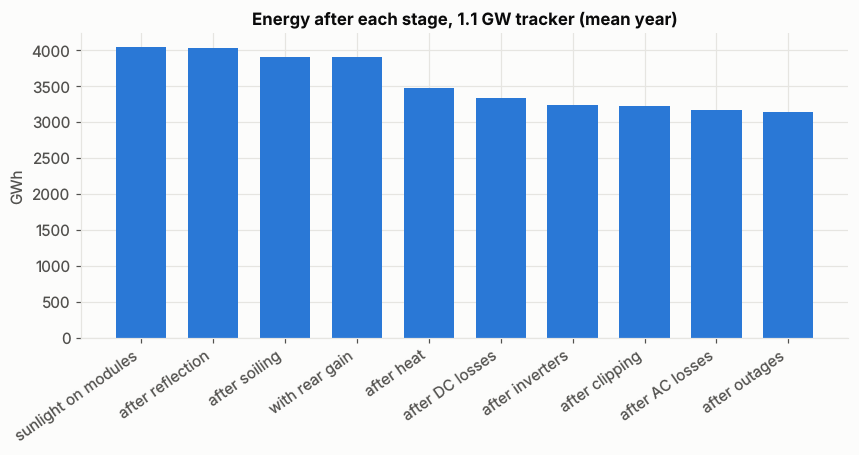

In [3]:
steps = w.drop('nameplate_x_ghi'); delta = steps.diff().fillna(steps.iloc[0])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(steps)), steps.values / 1e3, width=0.7, color=viz.SERIES[0])
NAMES = {'front_poa': 'sunlight on modules', 'after_iam': 'after reflection', 'after_soiling': 'after soiling',
         'after_bifacial_gain': 'with rear gain', 'after_temperature': 'after heat', 'after_dc_losses': 'after DC losses',
         'after_inverter_efficiency': 'after inverters', 'after_clipping': 'after clipping', 'after_ac_losses': 'after AC losses',
         'after_availability': 'after outages'}
ax.set_xticks(range(len(steps))); ax.set_xticklabels([NAMES[s] for s in steps.index], rotation=35, ha='right')
ax.set_title('Energy after each stage, 1.1 GW tracker (mean year)'); ax.set_ylabel('GWh')
plt.show()

In [4]:
y = pd.DataFrame(runs['shagaya-pv1-approximation']['result']['energy_by_year']).set_index('year')
y[['export_mwh', 'specific_yield_kwh_per_kwp']].round(0)

,export_mwh,specific_yield_kwh_per_kwp
year,,
2017,20829.0,1865.0
2018,20346.0,1822.0
2019,20359.0,1823.0
2020,20755.0,1859.0
2021,20777.0,1861.0
2022,20633.0,1848.0
2023,20378.0,1825.0


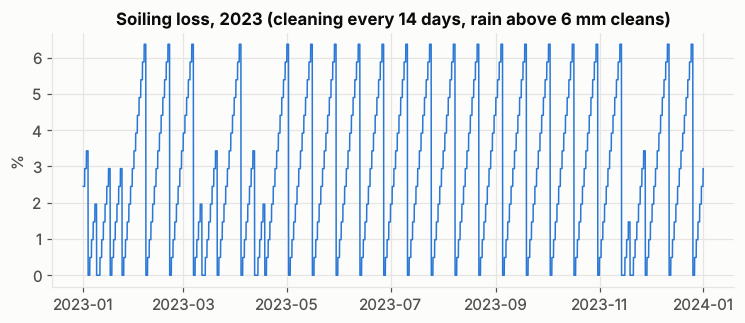

In [5]:
s = runs['shagaya-scale-pv-tracker']['pv']['soiling_ratio']
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot((1 - s['2023']) * 100, lw=1)
ax.set_title('Soiling loss, 2023 (cleaning every 14 days, rain above 6 mm cleans)'); ax.set_ylabel('%')
plt.show()